In [1]:
from google.colab import drive
from PIL import Image
from math import floor
import pandas as pd
import os
drive.mount('/content/drive')
BASE_DIR = "/content/drive/Shareddrives/CV_Project"
WORK_FOLDER = "Supervised_Classification"
DATA_DIR = os.path.join(BASE_DIR, WORK_FOLDER, "data")

Mounted at /content/drive


In [2]:
!mkdir "{DATA_DIR}"

mkdir: cannot create directory ‘/content/drive/Shareddrives/CV_Project/Supervised_Classification/data’: File exists


In [ ]:
!unzip "/content/drive/Shareddrives/CV_Project/archive.zip" -d "{DATA_DIR}"

Archive:  /content/drive/Shareddrives/CV_Project/archive.zip
replace /content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/Annotations.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [2]:
!ls -l "{DATA_DIR}/IndustryBiscuit"

total 123
-rw------- 1 root root 112576 Oct 11  2022 Annotations.csv
-rw------- 1 root root   4792 Oct 11  2022 DatasetFolder.py
drwx------ 2 root root   4096 Nov 30 05:15 DS_multiclass
drwx------ 2 root root   4096 Nov 30 04:32 Images


In [3]:
import os
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm # Import tqdm

imPath = os.path.join(DATA_DIR, 'IndustryBiscuit/Images')
anPath = os.path.join(DATA_DIR, 'IndustryBiscuit/Annotations.csv')
dsPath = os.path.join(DATA_DIR, 'IndustryBiscuit/DS_multiclass')

classes = ["Defect_No", "Defect_Shape", "Defect_Object", "Defect_Color"]

def make_dir_structure(base):
    for split in ["train", "valid", "test"]:
        for cls in classes:
            os.makedirs(os.path.join(base, split, cls), exist_ok=True)

make_dir_structure(dsPath)

df = pd.read_csv(anPath)[["file", "classDescription"]]

grouped = {cls: df[df["classDescription"] == cls]["file"].tolist() for cls in classes}

counts = {"train": {}, "valid": {}, "test": {}}

for cls in classes:
    images = grouped[cls]

    # split by 80/10/10
    train_files, test_files = train_test_split(images, test_size=0.2, random_state=42)
    valid_files, test_files = train_test_split(test_files, test_size=0.5, random_state=42)

    splits = {
        "train": train_files,
        "valid": valid_files,
        "test": test_files
    }

    for split in ["train", "valid", "test"]:
        cnt = 0
        # Add tqdm to the loop for a progress bar
        for fname in tqdm(splits[split], desc=f"Processing {cls} in {split} set"):
            img_path = os.path.join(imPath, fname)
            img = Image.open(img_path)

            img.save(os.path.join(dsPath, split, cls, fname))
            cnt += 1

        counts[split][cls] = cnt

print("\n=== Dataset Statistics ===")
for split in ["train", "valid", "test"]:
    print(f"\n[{split}]")
    for cls in classes:
        print(f"  {cls}: {counts[split][cls]}")

Processing Defect_No in train set:   0%|          | 0/1516 [00:00<?, ?it/s]

Processing Defect_No in valid set:   0%|          | 0/190 [00:00<?, ?it/s]

Processing Defect_No in test set:   0%|          | 0/190 [00:00<?, ?it/s]

Processing Defect_Shape in train set:   0%|          | 0/1488 [00:00<?, ?it/s]

Processing Defect_Shape in valid set:   0%|          | 0/186 [00:00<?, ?it/s]

Processing Defect_Shape in test set:   0%|          | 0/186 [00:00<?, ?it/s]

... (3 outputs left out)

Processing Defect_Color in train set:   0%|          | 0/409 [00:00<?, ?it/s]

Processing Defect_Color in valid set:   0%|          | 0/51 [00:00<?, ?it/s]

Processing Defect_Color in test set:   0%|          | 0/52 [00:00<?, ?it/s]


=== Dataset Statistics ===

[train]
  Defect_No: 1516
  Defect_Shape: 1488
  Defect_Object: 505
  Defect_Color: 409

[valid]
  Defect_No: 190
  Defect_Shape: 186
  Defect_Object: 63
  Defect_Color: 51

[test]
  Defect_No: 190
  Defect_Shape: 186
  Defect_Object: 64
  Defect_Color: 52


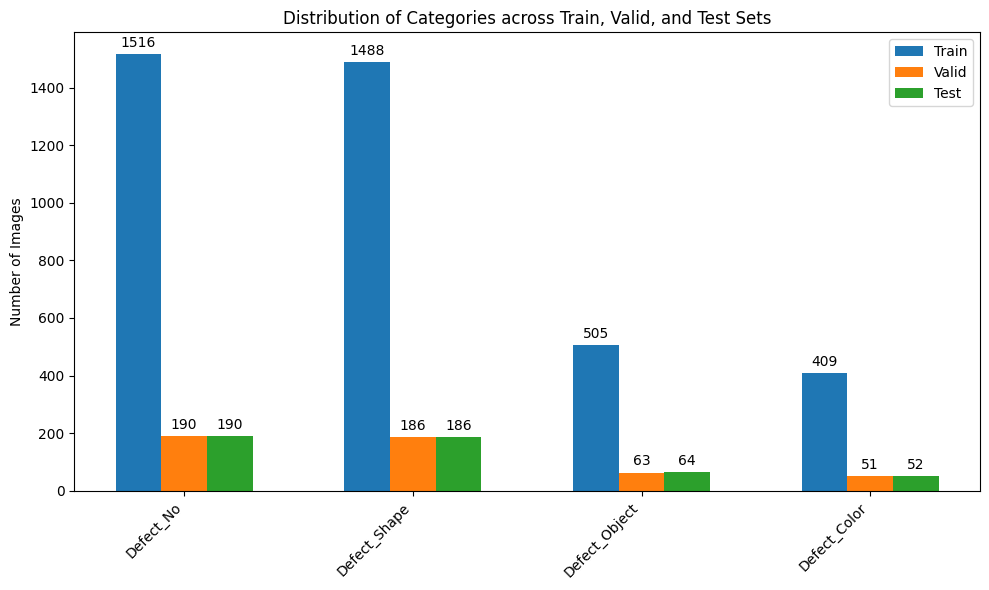

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
labels = classes
x = np.arange(len(labels))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

# Plot bars for each split
rects_train = ax.bar(x - width, [counts['train'][cls] for cls in classes], width, label='Train')
rects_valid = ax.bar(x, [counts['valid'][cls] for cls in classes], width, label='Valid')
rects_test = ax.bar(x + width, [counts['test'][cls] for cls in classes], width, label='Test')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Number of Images')
ax.set_title('Distribution of Categories across Train, Valid, and Test Sets')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.legend()

# Function to add labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects_train)
autolabel(rects_valid)
autolabel(rects_test)

fig.tight_layout()
plt.show()